# Alumno: Moises Lobayza
# Materia: Aprendizaje automatico 2

# **TP2: Clasificación de audio y reconocimiento de voz con PyTorch**

# **TUTORIAL A**




In [ ]:
%matplotlib inline

# Tutorial de clasificación de audio

**Autor:** [Winston Herring](https://github.com/winston6)

Este tutorial muestra cómo preparar correctamente un conjunto de datos de audio y posteriormente entrenar y evaluar una red neuronal para clasificarlos.

Primero, importaremos las bibliotecas principales de PyTorch, junto con `torchaudio`, `pandas` y `numpy`.

La biblioteca `torchaudio` está disponible en [GitHub](https://github.com/pytorch/audio) y puede instalarse siguiendo las instrucciones del sitio oficial.

In [ ]:

# Importamos PyTorch y las herramientas para construir y entrenar redes neuronales
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Herramientas para trabajar con datasets y transformaciones
from torchvision import datasets, transforms
from torch.utils.data import Dataset

# Biblioteca para procesar señales de audio
import torchaudio

# Bibliotecas para manejar tablas y arreglos numéricos
import pandas as pd
import numpy as np


# **Adaptación del entorno**
Aunque el tutorial original permite ejecutar el entrenamiento en CPU, optamos por utilizar una GPU NVIDIA Tesla T4 para reducir considerablemente los tiempos de procesamiento y optimizar el entrenamiento de la red neuronal.

Vamos a comprobar si hay disponible una GPU compatible con CUDA y seleccionar el dispositivo de procesamiento.

Ejecutar la red neuronal en una GPU puede reducir considerablemente el tiempo necesario para entrenar y evaluar el modelo.

In [ ]:

# Seleccionamos la GPU si CUDA está disponible; de lo contrario, usamos la CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mostramos el dispositivo seleccionado
print(device)


cuda


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4


## Importación del conjunto de datos

Utilizaremos el conjunto de datos **UrbanSound8K** para entrenar nuestra red neuronal. Está disponible gratuitamente en [UrbanSound Dataset](https://urbansounddataset.weebly.com/) y contiene 10 clases de sonidos, con más de 8.000 muestras de audio.

Una vez descargado el conjunto de datos comprimido, debemos extraerlo en nuestro directorio de trabajo actual.

Primero, examinaremos el archivo CSV que proporciona información sobre cada uno de los archivos de audio.

La biblioteca `pandas` nos permite leer el archivo CSV y utilizar el método `.iloc()` para acceder a sus datos.

**Para adaptar el tutorial original a Google Colab, incorporamos una descarga automática del conjunto de datos UrbanSound8K mediante un enlace público de Google Drive. Posteriormente, descomprimimos los archivos en el entorno de ejecución para conservar las rutas utilizadas en el tutorial.**

In [ ]:

# Instalamos gdown para descargar archivos públicos de Google Drive
!pip -q install gdown

# Enlace público del dataset UrbanSound8K
url = "https://drive.google.com/file/d/1-JRHsDvz4lhQUNTPB6vHo7bSKCGDu7mc/view?usp=sharing"

# Descargamos el archivo comprimido a Colab
!gdown --fuzzy "{url}" -O /content/UrbanSound8K.tar.gz

# Descomprimimos los archivos de audio
!tar -xzf /content/UrbanSound8K.tar.gz -C /content

# Verificamos que el CSV esté disponible
!ls /content/UrbanSound8K/metadata/


Downloading...
From (original): https://drive.google.com/uc?id=1-JRHsDvz4lhQUNTPB6vHo7bSKCGDu7mc
From (redirected): https://drive.google.com/uc?id=1-JRHsDvz4lhQUNTPB6vHo7bSKCGDu7mc&confirm=t&uuid=d3b8d8ca-eab5-43da-b7c5-68fdcc141a7f
To: /content/UrbanSound8K.tar.gz
100% 6.02G/6.02G [01:40<00:00, 60.0MB/s]
UrbanSound8K.csv


In [ ]:
# Leemos el CSV con los metadatos de los audios
csvData = pd.read_csv('./UrbanSound8K/metadata/UrbanSound8K.csv')

# Mostramos la primera fila
print(csvData.iloc[0, :])

slice_file_name    100032-3-0-0.wav
fsID                         100032
start                           0.0
end                        0.317551
salience                          1
fold                              5
classID                           3
class                      dog_bark
Name: 0, dtype: object


Las 10 clases de audio presentes en UrbanSound8K son: aire acondicionado, bocina de automóvil, niños jugando, ladridos de perro, perforación, motor en ralentí, disparos, martillo neumático, sirenas y música callejera.

Vamos a reproducir algunos archivos para escuchar sus sonidos. El primero corresponde a música callejera y el segundo a un aire acondicionado.

In [ ]:

# Importamos las herramientas de visualización de IPython
import IPython.display as ipd

# Reproducimos un audio de música callejera
display(ipd.Audio('./UrbanSound8K/audio/fold1/108041-9-0-5.wav'))

# Reproducimos un audio de aire acondicionado
display(ipd.Audio('./UrbanSound8K/audio/fold5/100852-0-0-19.wav'))


## Preparación de los datos

Ahora que conocemos el formato de las entradas del archivo CSV, podemos construir nuestro conjunto de datos.

Crearemos una clase contenedora (*wrapper*) utilizando `torch.utils.data.Dataset`, que se encargará de cargar los archivos y realizar las operaciones necesarias para preparar los datos.

El conjunto UrbanSound8K está dividido en 10 carpetas. Utilizaremos los datos de 9 carpetas para entrenar nuestra red neuronal y los de la décima carpeta para evaluarla.

Al inicializarse, la clase almacenará los nombres de los archivos, sus etiquetas y los números de las carpetas seleccionadas. La carga y preparación de los audios se realizará mediante el método `__getitem__()`.

Dentro de `__getitem__()`, utilizaremos `torchaudio.load()` para convertir los archivos WAV en tensores. Esta función devuelve una tupla que contiene el tensor de audio y su frecuencia de muestreo (44,1 kHz para los archivos considerados en el tutorial).

Como los audios pueden tener dos canales, utilizaremos una transformación para convertirlos a un solo canal (mono).

Posteriormente, prepararemos los datos para la red neuronal, que requiere entradas de 32.000 muestras. Sin embargo, muchos archivos de audio contienen más de 100.000 muestras.

Con una frecuencia de muestreo de 44,1 kHz, 32.000 muestras representan aproximadamente 700 milisegundos. Reduciendo la frecuencia de muestreo a unos 8 kHz, podemos representar aproximadamente 4 segundos utilizando 32.000 muestras.

El tutorial realiza esta reducción seleccionando una de cada cinco muestras del tensor original.

Como algunos archivos no contienen suficientes muestras, será necesario completar los tensores con ceros (*padding*).

Para aplicar este procedimiento, el tutorial establece una longitud inicial de 160.000 muestras.

In [ ]:

# Creamos una clase personalizada que hereda de Dataset
class UrbanSoundDataset(Dataset):

    def __init__(self, csv_path, file_path, folderList):

        # Leemos los metadatos del dataset
        csvData = pd.read_csv(csv_path)

        # Inicializamos las listas
        self.file_names = []
        self.labels = []
        self.folders = []

        # Recorremos las filas del CSV
        for i in range(len(csvData)):

            # Verificamos si el audio pertenece a una carpeta seleccionada
            if csvData.iloc[i, 5] in folderList:

                # Guardamos el nombre, la etiqueta y la carpeta
                self.file_names.append(csvData.iloc[i, 0])
                self.labels.append(csvData.iloc[i, 6])
                self.folders.append(csvData.iloc[i, 5])

        # Guardamos la ruta de los archivos y las carpetas seleccionadas
        self.file_path = file_path
        self.folderList = folderList

    def __getitem__(self, index):

        # Construimos la ruta del archivo según su carpeta y nombre
        path = (self.file_path + "fold" +
                str(self.folders[index]) + "/" +
                self.file_names[index])

        # Cargamos el audio como tensor y obtenemos su frecuencia
        soundData, sample_rate = torchaudio.load(path)

        # Convertimos el audio a mono promediando los canales
        soundData = soundData.mean(dim=0, keepdim=True)

        # Remuestreamos el audio a 8000 Hz
        soundData = torchaudio.functional.resample(
            soundData,
            orig_freq=sample_rate,
            new_freq=8000
        )

        # Ajustamos el audio a exactamente 32000 muestras
        if soundData.shape[1] < 32000:

            # Si es corto, completamos con ceros
            soundData = F.pad(
                soundData, (0, 32000 - soundData.shape[1])
            )
        else:

            # Si es largo, recortamos las muestras sobrantes
            soundData = soundData[:, :32000]

        # Devolvemos el audio procesado y su etiqueta
        return soundData, self.labels[index]

    def __len__(self):

        # Devolvemos la cantidad de archivos del dataset
        return len(self.file_names)


In [ ]:

# Definimos las rutas del dataset
csv_path = "./UrbanSound8K/metadata/UrbanSound8K.csv"
file_path = "./UrbanSound8K/audio/"

# Creamos un dataset utilizando solamente la carpeta 1
dataset_prueba = UrbanSoundDataset(
    csv_path, file_path, [1]
)

# Obtenemos el primer audio y su etiqueta
audio, etiqueta = dataset_prueba[0]

# Mostramos los resultados
print("Dimensiones del audio:", audio.shape)
print("Etiqueta numérica:", etiqueta)
print("Cantidad de audios:", len(dataset_prueba))


Dimensiones del audio: torch.Size([1, 32000])
Etiqueta numérica: 3
Cantidad de audios: 873


In [ ]:

# Definimos las rutas del dataset
csv_path = "./UrbanSound8K/metadata/UrbanSound8K.csv"
file_path = "./UrbanSound8K/audio/"

# Creamos el conjunto de entrenamiento con las carpetas 1 a 9
train_set = UrbanSoundDataset(csv_path, file_path, range(1, 10))

# Reservamos la carpeta 10 para las pruebas
test_set = UrbanSoundDataset(csv_path, file_path, [10])

# Mostramos la cantidad de audios de cada conjunto
print("Cantidad de audios de entrenamiento:", len(train_set))
print("Cantidad de audios de prueba:", len(test_set))


Cantidad de audios de entrenamiento: 7895
Cantidad de audios de prueba: 837


In [ ]:

# Configuramos la carga de datos según el dispositivo
# Si usamos GPU, activamos memoria fijada y un proceso de carga
kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

# Creamos el DataLoader de entrenamiento
# Procesa lotes de 128 audios y mezcla su orden
train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=128,
    shuffle=True,
    **kwargs
)

# Creamos el DataLoader de prueba
# Conservamos la configuración del tutorial original
test_loader = torch.utils.data.DataLoader(
    test_set,
    batch_size=128,
    shuffle=True,
    **kwargs
)


In [ ]:

# Obtenemos un lote de entrenamiento
audios, etiquetas = next(iter(train_loader))

# Mostramos sus dimensiones
print("Dimensiones del lote:", audios.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)

# Mostramos cuántos lotes tiene cada conjunto
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de prueba:", len(test_loader))


Dimensiones del lote: torch.Size([128, 1, 32000])
Dimensiones de las etiquetas: torch.Size([128])
Lotes de entrenamiento: 62
Lotes de prueba: 7


### **Resumen y verificación de la preparación de los datos**

En esta sección construimos una clase personalizada `UrbanSoundDataset`, utilizando la clase `Dataset` de PyTorch, para cargar y preparar las grabaciones de UrbanSound8K.

El procesamiento realizado incluye:

- **Carga de archivos:** lectura de los audios WAV y sus etiquetas correspondientes mediante los metadatos del CSV.
- **Conversión a mono:** reducción de los canales de audio a uno solo mediante el promedio de sus señales.
- **Remuestreo:** conversión de los audios a una frecuencia uniforme de 8.000 Hz.
- **Normalización de dimensiones:** ajuste de cada audio a 32.000 muestras mediante recorte o relleno con ceros (*padding*).
- **División de datos:** utilización de nueve carpetas para entrenamiento y una para evaluación.
- **Organización en lotes:** implementación de `DataLoader` con un tamaño de lote de 128 ejemplos.

**Adaptaciones realizadas:** debido a incompatibilidades con la versión actual de TorchAudio, reemplazamos `DownmixMono()` por una operación de promedio de canales. También sustituimos la selección de una de cada cinco muestras por un remuestreo a 8.000 Hz, para manejar correctamente los audios con diferentes frecuencias de muestreo y reducir el riesgo de aliasing.

**Resultados:** verificamos que los audios procesados tienen dimensiones `[1, 32000]` y que el DataLoader genera lotes de dimensiones `[128, 1, 32000]`. Obtuvimos 62 lotes de entrenamiento y 7 de prueba, sin errores durante las comprobaciones.

Con esto, los datos quedaron preparados para ser utilizados por la red neuronal de clasificación.

## Definición de la red neuronal

Para este tutorial utilizaremos una **red neuronal convolucional (CNN)** para procesar directamente los datos de audio sin procesar.

Habitualmente se aplican transformaciones más avanzadas a las señales de audio; sin embargo, las CNN también pueden procesar estos datos directamente con buena precisión.

La arquitectura utilizada está basada en la red **M5**, descrita en el siguiente artículo científico:

[Very Deep Convolutional Neural Networks for Raw Waveforms](https://arxiv.org/pdf/1610.00087.pdf).

Un aspecto importante de los modelos que procesan audio directamente es el **campo receptivo (*receptive field*)** de los filtros de su primera capa.

El primer filtro de nuestro modelo tiene una longitud de 80 muestras. Como procesamos audio a una frecuencia de 8 kHz, su campo receptivo abarca aproximadamente 10 milisegundos.

Este tamaño es comparable al utilizado en aplicaciones de procesamiento del habla, donde suelen emplearse campos receptivos de entre 20 y 40 milisegundos.

In [ ]:

# Definimos una red neuronal convolucional unidimensional
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()

        # Primer bloque: 1 canal de entrada y 128 filtros
        # Kernel de 80 muestras y desplazamiento de 4
        self.conv1 = nn.Conv1d(1, 128, 80, 4)
        self.bn1 = nn.BatchNorm1d(128)
        self.pool1 = nn.MaxPool1d(4)

        # Segundo bloque: 128 canales de entrada y salida
        self.conv2 = nn.Conv1d(128, 128, 3)
        self.bn2 = nn.BatchNorm1d(128)
        self.pool2 = nn.MaxPool1d(4)

        # Tercer bloque: aumentamos a 256 canales
        self.conv3 = nn.Conv1d(128, 256, 3)
        self.bn3 = nn.BatchNorm1d(256)
        self.pool3 = nn.MaxPool1d(4)

        # Cuarto bloque: aumentamos a 512 canales
        self.conv4 = nn.Conv1d(256, 512, 3)
        self.bn4 = nn.BatchNorm1d(512)
        self.pool4 = nn.MaxPool1d(4)

        # Reducimos la dimensión temporal a una posición
        self.avgPool = nn.AvgPool1d(30)

        # Capa completamente conectada para las 10 clases
        self.fc1 = nn.Linear(512, 10)

    def forward(self, x):

        # Primer bloque convolucional
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.pool1(x)

        # Segundo bloque convolucional
        x = self.conv2(x)
        x = F.relu(self.bn2(x))
        x = self.pool2(x)

        # Tercer bloque convolucional
        x = self.conv3(x)
        x = F.relu(self.bn3(x))
        x = self.pool3(x)

        # Cuarto bloque convolucional
        x = self.conv4(x)
        x = F.relu(self.bn4(x))
        x = self.pool4(x)

        # Reducimos la dimensión temporal mediante promedio
        x = self.avgPool(x)

        # Reorganizamos las dimensiones del tensor
        x = x.permute(0, 2, 1)

        # Transformamos las características en 10 puntuaciones
        x = self.fc1(x)

        # Devolvemos log-probabilidades para cada clase
        return F.log_softmax(x, dim=2)


# Creamos el modelo
model = Net()

# Lo enviamos al dispositivo seleccionado (CPU o GPU)
model.to(device)

# Mostramos su arquitectura
print(model)


Net(
  (conv1): Conv1d(1, 128, kernel_size=(80,), stride=(4,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (avgPool): AvgPool1d(kernel_size=(30,), stride=(30,), 

In [ ]:

# Creamos dos audios ficticios de 32000 muestras
entrada_prueba = torch.zeros(2, 1, 32000).to(device)

# Activamos el modo evaluación
model.eval()

# Ejecutamos una pasada hacia adelante sin calcular gradientes
with torch.no_grad():
    salida = model(entrada_prueba)

# Mostramos las dimensiones obtenidas
print("Entrada:", entrada_prueba.shape)
print("Salida:", salida.shape)

# Restauramos el modo entrenamiento
model.train()


Entrada: torch.Size([2, 1, 32000])
Salida: torch.Size([2, 1, 10])


Net(
  (conv1): Conv1d(1, 128, kernel_size=(80,), stride=(4,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (avgPool): AvgPool1d(kernel_size=(30,), stride=(30,), 

Utilizaremos la misma técnica de optimización presentada en el artículo científico: el optimizador **Adam**, con un decaimiento de pesos (*weight decay*) de 0,0001.

Inicialmente entrenaremos el modelo con una tasa de aprendizaje (*learning rate*) de 0,01, pero utilizaremos un planificador (*scheduler*) para reducirla a 0,001 durante el entrenamiento.

In [ ]:

# Configuramos el optimizador Adam
# Learning rate inicial de 0.01 y regularización de 0.0001
optimizer = optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=0.0001
)

# Reducimos el learning rate multiplicándolo por 0.1 cada 20 pasos
# del scheduler (en este tutorial, cada paso corresponderá a una época)
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=20,
    gamma=0.1
)


### **Resumen y verificación de la arquitectura neuronal**

En esta sección implementamos una red neuronal convolucional unidimensional (CNN), basada en la arquitectura M5, para clasificar señales de audio directamente a partir de sus muestras.

La red contiene cuatro bloques convolucionales que combinan operaciones `Conv1d`, normalización `BatchNorm1d`, activaciones ReLU y reducción dimensional mediante `MaxPool1d`.

Posteriormente, una capa de promedio y una capa lineal transforman las características extraídas en puntuaciones para las 10 categorías del dataset UrbanSound8K.

**Verificación:** realizamos una prueba utilizando dos audios ficticios con dimensiones `[2, 1, 32000]`. La red produjo correctamente una salida `[2, 1, 10]`, demostrando que la arquitectura puede procesar las entradas preparadas anteriormente.

Finalmente, configuramos el optimizador Adam con una tasa de aprendizaje inicial de 0,01, regularización de 0,0001 y un scheduler que reducirá progresivamente la tasa de aprendizaje durante el entrenamiento.

La arquitectura quedó definida y verificada, aunque todavía no fue entrenada ni evaluada su capacidad de clasificación.

### Recorrido de la señal dentro de la red neuronal

Entrada del audio:

`(1, 32000)`

- `1` = canal mono  
- `32000` = muestras del audio

---

#### Flujo capa por capa

```text
Entrada
(1, 32000)

→ Conv1d(1 → 128, kernel=80, stride=4)
(128, 7981)

→ BatchNorm1d + ReLU
(128, 7981)

→ MaxPool1d(4)
(128, 1995)

→ Conv1d(128 → 128, kernel=3)
(128, 1993)

→ BatchNorm1d + ReLU
(128, 1993)

→ MaxPool1d(4)
(128, 498)

→ Conv1d(128 → 256, kernel=3)
(256, 496)

→ BatchNorm1d + ReLU
(256, 496)

→ MaxPool1d(4)
(256, 124)

→ Conv1d(256 → 512, kernel=3)
(512, 122)

→ BatchNorm1d + ReLU
(512, 122)

→ MaxPool1d(4)
(512, 30)

→ AvgPool1d(30)
(512, 1)

→ Permute
(1, 512)

→ Linear(512 → 10)
(1, 10)

→ LogSoftmax
(1, 10)


### Arquitectura de la red neuronal CNN (M5)

La red procesa señales de audio de 4 segundos, muestreadas a 8 kHz, mediante cuatro bloques convolucionales.

| Etapa | Operaciones | Dimensión de salida |
|:---:|---|:---:|
| **Entrada** | Audio mono | `(1, 32000)` |
| **Bloque 1** | Conv1D (1→128, k=80, s=4) + BN + ReLU + MaxPool | `(128, 1995)` |
| **Bloque 2** | Conv1D (128→128, k=3) + BN + ReLU + MaxPool | `(128, 498)` |
| **Bloque 3** | Conv1D (128→256, k=3) + BN + ReLU + MaxPool | `(256, 124)` |
| **Bloque 4** | Conv1D (256→512, k=3) + BN + ReLU + MaxPool | `(512, 30)` |
| **Reducción** | AvgPool1D (30) | `(512, 1)` |
| **Reorganización** | Permute | `(1, 512)` |
| **Clasificación** | Linear (512→10) + LogSoftmax | `(1, 10)` |

**Interpretación:**

- **Convoluciones:** extraen características progresivamente más complejas.
- **Pooling:** reduce la dimensión temporal de las señales.
- **BatchNorm (BN):** normaliza las activaciones.
- **ReLU:** incorpora no linealidad.
- **Linear + LogSoftmax:** genera las log-probabilidades de las 10 clases.

*Nota: las dimensiones representan un solo audio, sin incluir la dimensión del batch.*


## Entrenamiento y evaluación de la red neuronal

Ahora definiremos una función de entrenamiento que introducirá los datos de entrenamiento en nuestro modelo y realizará los pasos de retropropagación (*backpropagation*) y optimización.

Durante este proceso, la red neuronal realizará predicciones, calculará el error mediante una función de pérdida y ajustará sus parámetros para mejorar progresivamente su capacidad de clasificación.

In [ ]:

# Definimos la función de entrenamiento
def train(model, epoch):

    # Activamos el modo entrenamiento
    model.train()

    # Recorremos los lotes del conjunto de entrenamiento
    for batch_idx, (data, target) in enumerate(train_loader):

        # Reiniciamos los gradientes acumulados
        optimizer.zero_grad()

        # Enviamos audios y etiquetas al dispositivo
        data = data.to(device)
        target = target.to(device)

        # Propagación hacia adelante: obtenemos las predicciones
        output = model(data)

        # Convertimos la salida de [batch, 1, 10] a [batch, 10]
        output = output.squeeze(1)

        # Calculamos la pérdida comparando predicciones y etiquetas
        loss = F.nll_loss(output, target)

        # Retropropagación: calculamos los gradientes
        loss.backward()

        # Actualizamos los pesos utilizando Adam
        optimizer.step()

        # Mostramos periódicamente el progreso del entrenamiento
        if batch_idx % log_interval == 0:

            print(
                "Época: {} [{}/{} ({:.0f}%)] Pérdida: {:.6f}".format(
                    epoch,
                    batch_idx * len(data),
                    len(train_loader.dataset),
                    100. * batch_idx / len(train_loader),
                    loss.item()
                )
            )


Ahora que tenemos una función de entrenamiento, necesitamos definir otra función para evaluar la precisión de la red neuronal.

Para ello, activaremos el modo `eval()` y realizaremos predicciones sobre el conjunto de prueba.

El método `eval()` cambia el comportamiento de determinadas capas de la red neuronal. Algunas, como la normalización por lotes (*Batch Normalization*) y Dropout, funcionan de manera diferente durante el entrenamiento y la evaluación.

Por esta razón, activar el modo evaluación es fundamental para obtener resultados correctos.

In [ ]:

# Definimos la función para evaluar la precisión de la red
def test(model, epoch):

    # Activamos el modo evaluación
    model.eval()

    # Inicializamos el contador de predicciones correctas
    correct = 0

    # Desactivamos el cálculo de gradientes
    with torch.no_grad():

        # Recorremos los lotes del conjunto de prueba
        for data, target in test_loader:

            # Enviamos los datos al dispositivo
            data = data.to(device)
            target = target.to(device)

            # Obtenemos las predicciones de la red
            output = model(data)

            # Ajustamos las dimensiones a [batch, 10]
            output = output.squeeze(1)

            # Seleccionamos la clase con mayor puntuación
            pred = output.argmax(dim=1)

            # Contamos las predicciones correctas
            correct += pred.eq(target).sum().item()

    # Calculamos la precisión porcentual
    accuracy = 100. * correct / len(test_loader.dataset)

    # Mostramos los resultados
    print(
        "\nPrueba - Época {}: Aciertos {}/{} ({:.2f}%)".format(
            epoch,
            correct,
            len(test_loader.dataset),
            accuracy
        )
    )


### Ejecución del entrenamiento y evaluación

Finalmente, entrenaremos y evaluaremos nuestra red neuronal durante 40 épocas.

Utilizaremos inicialmente una tasa de aprendizaje de 0,01. Después de completar las primeras 20 épocas, el scheduler la reducirá a 0,001 para continuar el entrenamiento.

Al finalizar cada época, evaluaremos la precisión del modelo sobre el conjunto de prueba para observar cómo evoluciona su rendimiento.

# **Guardado de checkpoints:**
Conectamos Google Drive para almacenar periódicamente el estado del entrenamiento y poder reanudarlo desde la última época completada en caso de desconexión de Google Colab, evitando perder el progreso.

In [ ]:
# Conectamos Google Drive para guardar los checkpoints
from google.colab import drive
drive.mount('/content/drive')

# Definimos dónde guardar los checkpoints
import os

checkpoint_dir = "/content/drive/MyDrive/csv/audio/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir, "modelo_m5_checkpoint.pth"
)

print("Directorio de checkpoints preparado")

Mounted at /content/drive
Directorio de checkpoints preparado


In [ ]:

# Mostramos estadísticas cada 20 lotes
log_interval = 20

# Comprobamos si existe un entrenamiento anterior
if os.path.exists(checkpoint_path):

    # Recuperamos el estado guardado
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])

    start_epoch = checkpoint["epoch"] + 1

    print(f"Reanudando desde la época {start_epoch}")

else:
    start_epoch = 1
    print("Iniciando entrenamiento desde cero")

# Entrenamos hasta completar 40 épocas
for epoch in range(start_epoch, 41):

    # Entrenamos y evaluamos
    train(model, epoch)
    test(model, epoch)

    # Actualizamos el learning rate
    scheduler.step()

    # Guardamos el estado completo al finalizar cada época
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict()
    }, checkpoint_path)

    print(f"Checkpoint guardado: época {epoch}/40")


Iniciando entrenamiento desde cero
Época: 1 [0/7895 (0%)] Pérdida: 2.377330
Época: 1 [2560/7895 (32%)] Pérdida: 2.039916
Época: 1 [5120/7895 (65%)] Pérdida: 1.853889
Época: 1 [7680/7895 (97%)] Pérdida: 1.719559

Prueba - Época 1: Aciertos 180/837 (21.51%)
Checkpoint guardado: época 1/40
Época: 2 [0/7895 (0%)] Pérdida: 1.717770
Época: 2 [2560/7895 (32%)] Pérdida: 1.529485
Época: 2 [5120/7895 (65%)] Pérdida: 1.539520
Época: 2 [7680/7895 (97%)] Pérdida: 1.306675

Prueba - Época 2: Aciertos 324/837 (38.71%)
Checkpoint guardado: época 2/40
Época: 3 [0/7895 (0%)] Pérdida: 1.463431
Época: 3 [2560/7895 (32%)] Pérdida: 1.609353
Época: 3 [5120/7895 (65%)] Pérdida: 1.424838
Época: 3 [7680/7895 (97%)] Pérdida: 1.358997

Prueba - Época 3: Aciertos 403/837 (48.15%)
Checkpoint guardado: época 3/40
Época: 4 [0/7895 (0%)] Pérdida: 1.403989
Época: 4 [2560/7895 (32%)] Pérdida: 1.279397
Época: 4 [5120/7895 (65%)] Pérdida: 1.172220
Época: 4 [7680/7895 (97%)] Pérdida: 1.102043

Prueba - Época 4: Aciertos 42

# **Guardado del modelo final:**
Verificamos que se hayan completado las 40 épocas y creamos una copia definitiva del checkpoint en Google Drive para conservar el modelo entrenado y evitar la pérdida de sus parámetros.

In [ ]:

import shutil
import torch
import os

# Definimos la ruta de la copia definitiva
ruta_final = os.path.join(
    checkpoint_dir, "modelo_m5_final_40epocas.pth"
)

# Verificamos la última época guardada
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Solo guardamos la copia si terminó el entrenamiento
if checkpoint["epoch"] == 40:
    shutil.copy2(checkpoint_path, ruta_final)
    print("Modelo final guardado correctamente.")
else:
    print("Entrenamiento incompleto. Última época:",
          checkpoint["epoch"])


Modelo final guardado correctamente.


### Resumen y resultados del entrenamiento y evaluación

En esta sección implementamos las funciones de entrenamiento y evaluación de nuestra red neuronal convolucional (CNN), utilizando el optimizador Adam y la función de pérdida `NLLLoss`.

El entrenamiento se realizó durante **40 épocas**, utilizando 7.895 audios para entrenamiento y 837 para evaluación. La tasa de aprendizaje inicial fue de 0,01 y se redujo a 0,001 después de las primeras 20 épocas mediante un scheduler.

**Resultados obtenidos:**

- **Precisión final:** 65,95 %, con 552 clasificaciones correctas sobre 837 audios.
- **Evolución del aprendizaje:** la pérdida de entrenamiento disminuyó considerablemente, mientras que la precisión de evaluación presentó fluctuaciones entre épocas.
- **Rendimiento:** el modelo consiguió aprender patrones relevantes de los sonidos urbanos, aunque todavía presenta errores de clasificación.

**Dificultades técnicas y soluciones:**

Inicialmente ejecutamos el entrenamiento utilizando CPU, con tiempos aproximados de 15 a 20 minutos por época. Durante la época 35 se produjo una desconexión del entorno de Google Colab y perdimos los pesos entrenados.

Para solucionarlo, activamos una GPU NVIDIA Tesla T4, reduciendo el tiempo de procesamiento a aproximadamente 1–2 minutos por época.

Además, implementamos un sistema de **checkpoints automáticos en Google Drive**, que guarda los pesos del modelo, el estado del optimizador, el scheduler y la última época completada. Esto permite reanudar el entrenamiento después de posibles interrupciones.

Finalmente, completamos las 40 épocas y guardamos una copia definitiva del modelo entrenado.

**Conclusión:** logramos implementar, entrenar y evaluar una CNN para clasificación de audio, verificando tanto su funcionamiento como su capacidad de aprendizaje. También incorporamos mejoras de eficiencia y recuperación que hacen más robusto el procedimiento original.

La precisión obtenida corresponde al conjunto reservado para evaluación, consultado después de cada época; por lo tanto, no debe interpretarse como una evaluación final completamente independiente si sus resultados influyen en decisiones posteriores sobre el modelo.

## Conclusión

Si entrenamos la red neuronal utilizando 9 carpetas del conjunto UrbanSound8K, deberíamos obtener una precisión superior al 50 % al finalizar el entrenamiento.

Entrenar con menos carpetas generalmente produce una precisión menor, pero puede ser necesario cuando los tiempos de procesamiento son demasiado elevados.

Es posible conseguir una mayor precisión utilizando redes neuronales convolucionales (CNN) más profundas, aunque esto implica un mayor consumo de memoria.

Para aplicaciones de audio más avanzadas, como el reconocimiento de voz, también se utilizan redes neuronales recurrentes (RNN).

Existen otros métodos de preprocesamiento de audio, como la extracción de los **coeficientes cepstrales en las frecuencias de Mel (MFCC)**, que permiten representar las características relevantes de las señales de una manera más compacta.

### **Resultados de nuestra implementación**

En nuestra implementación, entrenamos la CNN durante 40 épocas con 7.895 archivos de audio y evaluamos su rendimiento sobre 837 grabaciones.

Obtuvimos una **precisión final del 65,95 %**, equivalente a 552 clasificaciones correctas, superando el 50 % de precisión señalado como referencia en el tutorial original.

Durante el desarrollo comprobamos la importancia del preprocesamiento de las señales, la configuración de los hiperparámetros y el aprovechamiento de la GPU para acelerar el entrenamiento.

También incorporamos checkpoints automáticos, permitiendo recuperar el estado del modelo ante interrupciones y evitando repetir entrenamientos completos.

Como posibles mejoras futuras, podríamos experimentar con arquitecturas convolucionales más profundas, representaciones espectrales como los MFCC y procedimientos de validación adicionales para evaluar la capacidad de generalización.


### Referencias

1. Herring, W. **Audio Classifier Tutorial**. PyTorch Tutorials.  
   https://colab.research.google.com/github/pytorch/tutorials/blob/gh-pages/_downloads/audio_classifier_tutorial.ipynb

2. Salamon, J., Jacoby, C. y Bello, J. P. (2014). **A Dataset and Taxonomy for Urban Sound Research**. ACM Multimedia.  
   https://zenodo.org/records/1203745

3. Dai, W., Dai, C., Qu, S., Li, J. y Das, S. (2017). **Very Deep Convolutional Neural Networks for Raw Waveforms**. ICASSP.  
   https://arxiv.org/abs/1610.00087

4. PyTorch. **Documentación oficial de PyTorch y TorchAudio**.  
   https://docs.pytorch.org/


# **TUTORIAL B**

# Reconocimiento de voz con Wav2Vec2

**Autor:** Moto Hira (moto@meta.com)

Este tutorial muestra cómo realizar reconocimiento automático de voz utilizando modelos preentrenados de **Wav2Vec 2.0**, basados en la arquitectura descrita en el siguiente artículo científico:

[Wav2Vec 2.0: A Framework for Self-Supervised Learning of Speech Representations](https://arxiv.org/abs/2006.11477)

## Visión general

El proceso de reconocimiento de voz comprende las siguientes etapas:

1. **Extracción de características acústicas:** obtener información relevante a partir de la forma de onda del audio.
2. **Clasificación de características:** estimar las clases correspondientes a las características acústicas en cada intervalo temporal (*frame*).
3. **Generación de hipótesis:** producir una posible transcripción a partir de la secuencia de probabilidades de las clases.

La biblioteca `torchaudio` proporciona acceso a los pesos de modelos preentrenados y a información asociada, como la frecuencia de muestreo esperada y las etiquetas de las clases.

Estos elementos se encuentran agrupados y disponibles mediante el módulo `torchaudio.pipelines`.

# Preparación

In [ ]:

# Importamos PyTorch y TorchAudio
import torch
import torchaudio

# Mostramos las versiones de las bibliotecas
print("Versión de PyTorch:", torch.__version__)
print("Versión de TorchAudio:", torchaudio.__version__)

# Fijamos una semilla para facilitar la reproducibilidad
torch.random.manual_seed(0)

# Seleccionamos GPU si está disponible; de lo contrario, CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mostramos el dispositivo seleccionado
print("Dispositivo:", device)


Versión de PyTorch: 2.11.0+cu130
Versión de TorchAudio: 2.11.0+cu130
Dispositivo: cuda


In [ ]:

# Importamos las herramientas de visualización
import IPython
import matplotlib.pyplot as plt

# Importamos la herramienta de descarga de archivos
from urllib.request import urlretrieve

# URL del audio utilizado en el tutorial oficial
url_audio = "https://pytorch-tutorial-assets.s3.amazonaws.com/VOiCES_devkit/source-16k/train/sp0307/Lab41-SRI-VOiCES-src-sp0307-ch127535-sg0042.wav"

# Definimos dónde guardar el archivo en Colab
SPEECH_FILE = "/content/speech.wav"

# Descargamos el archivo de voz
urlretrieve(url_audio, SPEECH_FILE)

# Mostramos la ruta del archivo
print("Audio descargado correctamente:", SPEECH_FILE)


Audio descargado correctamente: /content/speech.wav


**Adaptación del tutorial:** reemplazamos la función interna `_download_asset()` de TorchAudio por `urlretrieve()` de Python para garantizar la compatibilidad con las versiones actuales de las bibliotecas y descargar el archivo de audio utilizado en el tutorial.

## Creación del pipeline

Primero, crearemos un modelo Wav2Vec2 que realizará la extracción de características acústicas y su clasificación.

En TorchAudio existen dos tipos de pesos preentrenados para Wav2Vec2: aquellos que fueron ajustados para tareas de reconocimiento automático de voz (ASR) y aquellos que no recibieron ese ajuste específico.

Los modelos Wav2Vec2 y HuBERT se entrenan mediante **aprendizaje autosupervisado**. Inicialmente aprenden representaciones utilizando únicamente datos de audio y, posteriormente, pueden ajustarse (*fine-tuning*) para una tarea específica utilizando etiquetas adicionales.

Los pesos preentrenados también pueden adaptarse a otras tareas, aunque este tutorial no aborda ese procedimiento.

En este caso utilizaremos el modelo `WAV2VEC2_ASR_BASE_960H`.

TorchAudio proporciona varios modelos preentrenados disponibles mediante `torchaudio.pipelines`. La documentación oficial contiene información sobre sus características y entrenamiento.

El objeto `bundle` proporciona una interfaz para crear el modelo y acceder a información asociada, como la frecuencia de muestreo requerida y las etiquetas de las clases.

In [ ]:

# Seleccionamos el modelo Wav2Vec2 preentrenado
# y ajustado para reconocimiento automático de voz
bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H

# Mostramos la frecuencia de muestreo que requiere el modelo
print("Frecuencia de muestreo:", bundle.sample_rate)

# Mostramos las etiquetas de los símbolos reconocibles
print("Etiquetas:", bundle.get_labels())


Frecuencia de muestreo: 16000
Etiquetas: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


El modelo puede construirse de la siguiente manera. Este procedimiento descargará automáticamente los pesos preentrenados y los cargará en la red neuronal.

In [ ]:

# Construimos el modelo y descargamos los pesos preentrenados
model = bundle.get_model().to(device)

# Activamos el modo evaluación porque realizaremos inferencia
model.eval()

# Mostramos la clase del modelo cargado
print(model.__class__)


Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960_asr_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960_asr_ls960.pth


100%|██████████| 360M/360M [00:06<00:00, 55.2MB/s]


<class 'torchaudio.models.wav2vec2.model.Wav2Vec2Model'>


## Carga de datos

Utilizaremos una grabación de voz del conjunto de datos [VOiCES](https://iqtlabs.github.io/voices/), distribuido bajo licencia Creative Commons BY 4.0.

Primero, reproduciremos el audio para escuchar su contenido.

Para cargar los datos utilizaremos `torchaudio.load()`.

Si la frecuencia de muestreo del archivo es diferente de la esperada por el modelo, podemos utilizar `torchaudio.functional.resample()` para adaptarla.

**Observaciones:**

- `torchaudio.functional.resample()` también permite trabajar con tensores almacenados en una GPU mediante CUDA.
- Cuando se realiza repetidamente un remuestreo entre las mismas frecuencias, utilizar `torchaudio.transforms.Resample` puede mejorar el rendimiento.

In [ ]:
display(IPython.display.Audio(SPEECH_FILE))


In [ ]:

# Cargamos el archivo como tensor y obtenemos su frecuencia
waveform, sample_rate = torchaudio.load(SPEECH_FILE)

# Mostramos las características originales del audio
print("Dimensiones originales:", waveform.shape)
print("Frecuencia original:", sample_rate, "Hz")

# Enviamos el tensor al dispositivo seleccionado (CPU o GPU)
waveform = waveform.to(device)

# Si la frecuencia no coincide con la requerida por Wav2Vec2,
# realizamos un remuestreo para adaptarla
if sample_rate != bundle.sample_rate:
    waveform = torchaudio.functional.resample(
        waveform,
        orig_freq=sample_rate,
        new_freq=bundle.sample_rate
    )

# Verificamos las dimensiones después del procesamiento
print("Dimensiones procesadas:", waveform.shape)
print("Frecuencia requerida:", bundle.sample_rate, "Hz")


Dimensiones originales: torch.Size([1, 54400])
Frecuencia original: 16000 Hz
Dimensiones procesadas: torch.Size([1, 54400])
Frecuencia requerida: 16000 Hz


## Extracción de características acústicas

El siguiente paso consiste en extraer las características acústicas de la señal de audio.

**Nota:** los modelos Wav2Vec2 ajustados para reconocimiento automático de voz (ASR) pueden realizar la extracción de características y la clasificación en un solo paso. Sin embargo, para fines didácticos, en este tutorial también mostraremos cómo realizar la extracción de características por separado.

In [ ]:

# Desactivamos el cálculo de gradientes porque no entrenaremos el modelo
with torch.inference_mode():

    # Extraemos las representaciones acústicas generadas
    # por las diferentes capas Transformer
    features, _ = model.extract_features(waveform)

# Verificamos las características extraídas
print("Cantidad de capas:", len(features))
print("Dimensión del primer tensor:", features[0].shape)


Cantidad de capas: 12
Dimensión del primer tensor: torch.Size([1, 169, 768])


Las características obtenidas se presentan como una lista de tensores. Cada tensor representa la salida de una capa Transformer.

A continuación, visualizaremos estas características mediante gráficos para observar las representaciones generadas en cada capa.

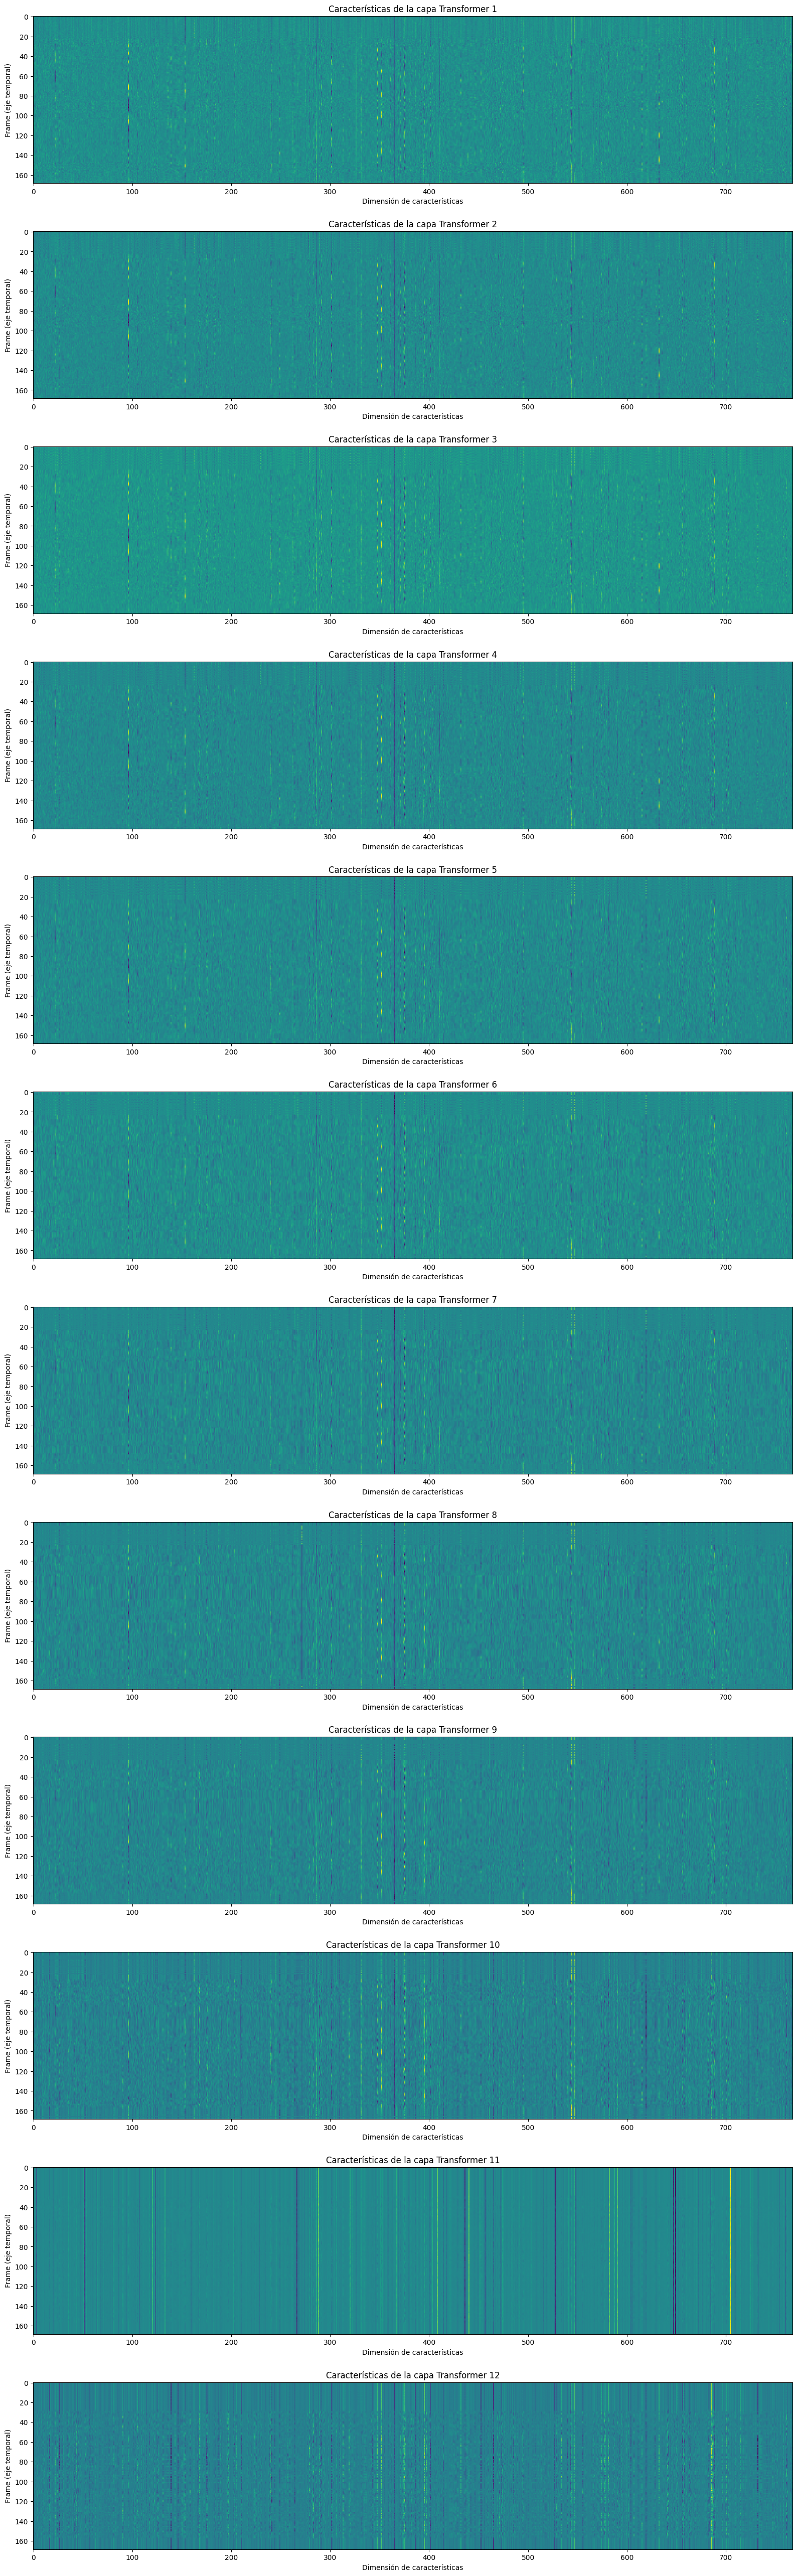

In [ ]:

# Creamos un gráfico para cada capa Transformer
fig, ax = plt.subplots(
    len(features), 1,
    figsize=(16, 4.3 * len(features))
)

# Recorremos las características de cada capa
for i, feats in enumerate(features):

    # Representamos las activaciones de la primera muestra
    # como un mapa de calor
    ax[i].imshow(feats[0].cpu(), interpolation="nearest")

    # Identificamos cada capa
    ax[i].set_title(f"Características de la capa Transformer {i+1}")

    # Eje horizontal: dimensiones de características
    ax[i].set_xlabel("Dimensión de características")

    # Eje vertical: intervalos temporales del audio
    ax[i].set_ylabel("Frame (eje temporal)")

# Ajustamos la distribución de los gráficos
fig.tight_layout()

# Mostramos los gráficos
plt.show()


## Clasificación de características

Una vez extraídas las características acústicas, el siguiente paso consiste en clasificarlas en un conjunto de categorías.

El modelo Wav2Vec2 proporciona un método que permite realizar la extracción de características y su clasificación en un solo paso.

In [ ]:

# Desactivamos el cálculo de gradientes porque realizaremos inferencia
with torch.inference_mode():

    # Procesamos el audio completo para extraer sus características
    # y obtener las puntuaciones de clasificación
    emission, _ = model(waveform)

# Mostramos las dimensiones del tensor de salida
print("Dimensiones de emission:", emission.shape)


Dimensiones de emission: torch.Size([1, 169, 29])


La salida del modelo se presenta en forma de **logits**, es decir, puntuaciones numéricas que todavía no representan probabilidades normalizadas.

Vamos a visualizar estos resultados.

Etiquetas: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


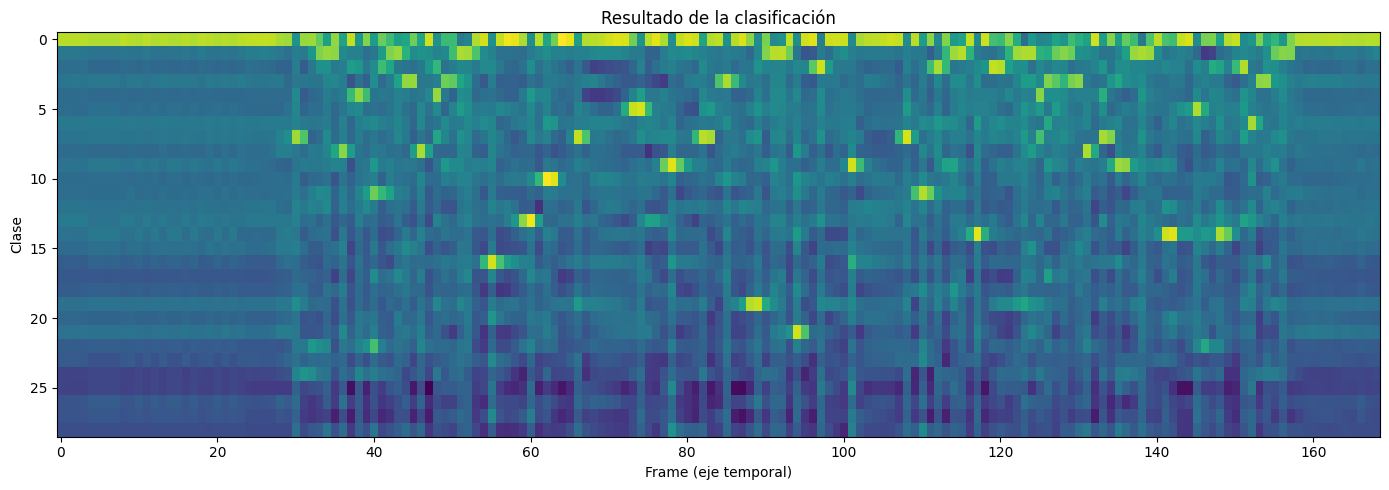

In [ ]:

# Creamos una figura para visualizar los resultados
plt.figure(figsize=(14, 5))

# Representamos las puntuaciones de clasificación
# Seleccionamos el primer audio y trasladamos los datos a CPU
# Transponemos el tensor para mostrar clases en Y y tiempo en X
plt.imshow(
    emission[0].cpu().T,
    interpolation="nearest",
    aspect="auto"
)

# Agregamos títulos y etiquetas en español
plt.title("Resultado de la clasificación")
plt.xlabel("Frame (eje temporal)")
plt.ylabel("Clase")

# Ajustamos la distribución
plt.tight_layout()

# Mostramos las etiquetas disponibles
print("Etiquetas:", bundle.get_labels())

# Visualizamos el gráfico
plt.show()


Podemos observar que existen indicaciones fuertes de determinadas etiquetas a lo largo de la secuencia temporal.

Esto significa que, en distintos momentos del audio, el modelo asigna puntuaciones más altas a ciertos símbolos, que posteriormente se utilizarán para generar la transcripción.

## Generación de transcripciones

A partir de la secuencia de probabilidades de las etiquetas, ahora queremos generar transcripciones. El proceso de generar posibles transcripciones se denomina **decodificación (*decoding*)**.

La decodificación es más compleja que una clasificación simple, porque la decisión tomada en un instante determinado puede depender de las observaciones anteriores y posteriores.

Por ejemplo, consideremos las palabras inglesas `night` (noche) y `knight` (caballero). Aunque sus probabilidades de aparición son diferentes, para transcribir correctamente una expresión como *a knight with a sword* (un caballero con una espada), el decodificador necesita considerar suficiente contexto antes de tomar una decisión definitiva.

Existen diferentes técnicas de decodificación que pueden utilizar recursos externos, como diccionarios y modelos de lenguaje.

En este tutorial, por simplicidad, utilizaremos **decodificación greedy**, que no necesita estos componentes externos y simplemente selecciona el símbolo con mayor puntuación en cada instante.

Por lo tanto, esta técnica no incorpora contexto lingüístico adicional durante la decodificación y genera una única transcripción.

Comenzaremos definiendo nuestro algoritmo de decodificación greedy.

In [ ]:

# Definimos un decodificador Greedy basado en CTC
class GreedyCTCDecoder(torch.nn.Module):

    def __init__(self, labels, blank=0):
        super().__init__()

        # Guardamos las etiquetas de los símbolos reconocibles
        self.labels = labels

        # Definimos el índice del símbolo vacío (blank)
        self.blank = blank

    def forward(self, emission: torch.Tensor) -> str:
        """
        Recibe un tensor de logits con dimensiones
        [cantidad de frames, cantidad de etiquetas].

        Devuelve una cadena de texto con la transcripción.
        """

        # Seleccionamos el símbolo con mayor puntuación
        # para cada frame del audio
        indices = torch.argmax(emission, dim=-1)

        # Eliminamos las repeticiones consecutivas
        indices = torch.unique_consecutive(indices, dim=-1)

        # Eliminamos los símbolos vacíos de CTC
        indices = [i for i in indices if i != self.blank]

        # Convertimos los índices en caracteres y los concatenamos
        return "".join([self.labels[i] for i in indices])


Ahora crearemos una instancia del decodificador y la utilizaremos para obtener la transcripción del audio.

In [ ]:

# Creamos el decodificador con las etiquetas del modelo
decoder = GreedyCTCDecoder(labels=bundle.get_labels())

# Decodificamos las predicciones del primer audio
transcript = decoder(emission[0])


Vamos a comprobar el resultado obtenido y escuchar nuevamente la grabación original para comparar la transcripción con el contenido del audio.

In [ ]:

# Mostramos la transcripción generada por el modelo
print("Transcripción original:", transcript)

# Reemplazamos el separador de palabras por espacios
print("Transcripción legible:", transcript.replace("|", " "))

# Reproducimos nuevamente el audio original
display(IPython.display.Audio(SPEECH_FILE))


Transcripción original: I|HAD|THAT|CURIOSITY|BESIDE|ME|AT|THIS|MOMENT|
Transcripción legible: I HAD THAT CURIOSITY BESIDE ME AT THIS MOMENT 


El modelo de reconocimiento automático de voz (ASR) fue ajustado utilizando una función de pérdida denominada **Clasificación Temporal Conexionista (Connectionist Temporal Classification, CTC)**.

CTC permite entrenar modelos que relacionan secuencias de entrada y salida sin necesitar una correspondencia exacta entre cada instante del audio y cada carácter.

Utiliza un símbolo especial denominado *blank* (ε), que representa una posición sin carácter emitido. Durante la decodificación, estos símbolos se eliminan.

Para obtener más información sobre CTC, puede consultarse el artículo [Sequence Modeling with CTC](https://distill.pub/2017/ctc/).

### **Resultado de la transcripción**

El modelo Wav2Vec2 logró transcribir correctamente la grabación de voz utilizando el decodificador Greedy CTC.

Se comprobó que las predicciones de símbolos generadas por la red neuronal pueden transformarse en una secuencia de palabras comprensible, eliminando repeticiones consecutivas y símbolos vacíos.

La transcripción obtenida coincide con el contenido de la grabación, verificando el funcionamiento del sistema de reconocimiento automático de voz para este ejemplo.

## Conclusión

En este tutorial aprendimos a utilizar `torchaudio.pipelines.Wav2Vec2ASRBundle` para realizar la extracción de características acústicas y el reconocimiento automático de voz.

La construcción del modelo y la obtención de las predicciones (*emissions*) pueden realizarse con solo dos líneas de código:

```python
model = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H.get_model()
emission, _ = model(waveform)
```

### **Resumen y resultados de nuestra implementación**

En este tutorial implementamos un sistema de reconocimiento automático de voz utilizando el modelo preentrenado **Wav2Vec2 Base**, disponible en TorchAudio.

A diferencia del Tutorial A, donde entrenamos una CNN para clasificar sonidos urbanos, en esta oportunidad utilizamos un modelo previamente entrenado para transformar una grabación de voz en texto.

Durante el procedimiento:

- **Preparamos el audio:** cargamos una grabación de 3,4 segundos, con una frecuencia de muestreo de 16.000 Hz.
- **Extrajimos características acústicas:** utilizamos las 12 capas Transformer de Wav2Vec2 y visualizamos sus representaciones mediante mapas de calor.
- **Clasificamos las características:** obtuvimos un tensor de dimensiones `[1, 169, 29]`, correspondiente a 169 frames y 29 símbolos posibles.
- **Generamos la transcripción:** implementamos un decodificador Greedy CTC para convertir las predicciones en texto legible.

**Resultado obtenido:**

El modelo generó la siguiente transcripción:

> I HAD THAT CURIOSITY BESIDE ME AT THIS MOMENT

Al reproducir el audio original, comprobamos que la transcripción coincidía con el contenido de la grabación.

**Adaptaciones realizadas:**

Reemplazamos la función interna `_download_asset()` de TorchAudio por `urlretrieve()` de Python para descargar el archivo de audio, manteniendo la compatibilidad con el entorno de Google Colab.

También incorporamos comentarios explicativos, verificaciones de dimensiones y una conversión del separador `|` a espacios convencionales para facilitar la lectura de la transcripción.

**Conclusión final:**

El tutorial permitió comprender cómo un sistema de reconocimiento de voz combina la extracción de características acústicas, el procesamiento contextual mediante Transformers y la decodificación CTC para transformar señales de audio en texto.

La prueba realizada fue satisfactoria, aunque corresponde a una única grabación y no permite establecer la precisión general del modelo. Para una evaluación más completa sería necesario utilizar múltiples audios y métricas como la tasa de error por palabra (*Word Error Rate*, WER).

## Referencias bibliográficas

1. Hira, M. **Speech Recognition with Wav2Vec2**. PyTorch, TorchAudio Tutorials.  
   https://github.com/pytorch/audio/blob/main/examples/tutorials/speech_recognition_pipeline_tutorial.py

2. Baevski, A., Zhou, H., Mohamed, A. y Auli, M. (2020). **wav2vec 2.0: A Framework for Self-Supervised Learning of Speech Representations**. Advances in Neural Information Processing Systems (NeurIPS).  
   https://arxiv.org/abs/2006.11477

3. Hannun, A. (2017). **Sequence Modeling with CTC**. Distill.  
   https://distill.pub/2017/ctc/

4. PyTorch. **Documentación oficial de TorchAudio — Speech Recognition with Wav2Vec2**.  
   https://docs.pytorch.org/audio/main/tutorials/speech_recognition_pipeline_tutorial.html

5. IQT Labs. **VOiCES: Voices Obscured in Complex Environmental Settings**. Conjunto de datos de voz utilizado en el tutorial.  
   https://iqtlabs.github.io/voices/